In [82]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 15)
pd.set_option("display.precision", 3)
RANDOM_STATE = 42


In [83]:
df=pd.read_csv('data clean/cardio_cleaned.csv')

In [84]:

DATA_PATH = Path("cardio_train.csv")

TARGET = "cardio"

NUMERIC_FEATURES = [ "age_years","height","weight","ap_hi","ap_lo","bmi","pulse_pressure",
                     "map"]

CATEGORICAL_FEATURES = ["gender","cholesterol","gluc","smoke","alco","active","bmi_category",
                        "age_group","bp_category","cholesterol_category","glucose_category","lifestyle_risk_count","high_risk_count"]

ID_COLUMNS = ["id"]

DATETIME_COLUMNS = []

EXCLUDED_COLUMNS = []

TARGET_LABELS = {0: "no cardiovascular disease",1: "cardiovascular disease"}

POSITIVE_CLASS = 1

In [85]:
for col in CATEGORICAL_FEATURES:
    print(f"\n{col}")
    display(df[col].value_counts(dropna=False).rename("rows").to_frame())

if NUMERIC_FEATURES:
    display(df[NUMERIC_FEATURES].describe().T)
    display(pd.DataFrame({
        "most_frequent_value": [df[c].mode().iloc[0] if not df[c].mode().empty else np.nan
                                for c in NUMERIC_FEATURES],
        "frequency_pct": [100 * df[c].value_counts(normalize=True).iloc[0]
                          if df [c].notna().any() else np.nan for c in NUMERIC_FEATURES]
    }, index=NUMERIC_FEATURES))


gender


,rows
gender,
1,45530
2,24470



cholesterol


,rows
cholesterol,
1,52385
2,9549
3,8066



gluc


...

,rows
lifestyle_risk_count,
0,49486
1,17638
2,2594
3,282



high_risk_count


,rows
high_risk_count,
0,31224
1,19723
2,12367
3,5219
4,1467


,count,mean,std,min,25%,50%,75%,max
age_years,70000.0,53.303,6.760,30.00,48.00,54.00,58.00,65.00
height,70000.0,164.415,7.923,120.00,159.00,165.00,170.00,207.00
weight,70000.0,74.211,14.386,30.00,65.00,72.00,82.00,200.00
ap_hi,69669.0,127.061,17.029,60.00,120.00,120.00,140.00,240.00
ap_lo,68891.0,81.306,9.483,30.00,80.00,80.00,90.00,182.00
bmi,70000.0,27.493,5.290,10.73,23.88,26.37,30.18,108.17
pulse_pressure,68678.0,45.372,11.678,5.00,40.00,40.00,50.00,140.00
map,68678.0,96.426,11.062,46.67,93.33,93.33,103.33,186.67


,most_frequent_value,frequency_pct
age_years,54.00,8.516
height,165.00,8.437
weight,65.00,5.500
ap_hi,120.00,39.757
ap_lo,80.00,50.583
bmi,23.88,1.654
pulse_pressure,40.00,49.870
map,93.33,34.737


In [ ]:
TARGET_LABELS = {
    0: "No cardiovascular disease",
    1: "Cardiovascular disease"
}

POSITIVE_CLASS = 1
print(f"Rows excluded from class comparisons because target is missing: {df[TARGET].isna().sum():,}")
df = df.loc[df[TARGET].notna()].copy()
assert not df.empty, "No labeled rows remain."

if NUMERIC_FEATURES:
    assert not np.isinf(df[NUMERIC_FEATURES].to_numpy(dtype=float)).any(), "Investigate infinite values."
    NUMERIC_FEATURES = [c for c in NUMERIC_FEATURES if df[c].notna().any()]
    print("Numerical features with at least one observed value:", NUMERIC_FEATURES)

observed_classes = sorted(df[TARGET].unique(), key=str)
label_lookup = {value: str(TARGET_LABELS.get(value, value)) for value in observed_classes}
assert len(set(label_lookup.values())) == len(label_lookup), "Target display labels must be distinct."
CLASS_COL = "__target_label__"
assert CLASS_COL not in df.columns
df[CLASS_COL] = df[TARGET].map(label_lookup)
class_order = [label_lookup[v] for v in observed_classes]
class_colors = dict(zip(class_order, sns.color_palette("colorblind", len(class_order))))
IS_BINARY = len(observed_classes) == 2 and POSITIVE_CLASS in observed_classes

for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype("string").fillna("<Missing>")

category_orders = {c: df[c].value_counts().index.tolist() for c in CATEGORICAL_FEATURES}
print(f"Analysis population: {len(df):,} rows; classes: {class_order}")

Rows excluded from class comparisons because target is missing: 0
Numerical features with at least one observed value: ['age_years', 'height', 'weight', 'ap_hi', 'ap_lo', 'bmi', 'pulse_pressure', 'map']
Analysis population: 70,000 rows; classes: ['No cardiovascular disease', 'Cardiovascular disease']


In [ ]:

class_colors = {
    0: "#55b4a5",
    1: "#9274c9"
}
def label_bars(ax, fmt="%.0f"):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt)


def subplot_grid(n, ncols=2, width=6, height=4): 
    """Return a figure and n usable axes; hide any unused panels."""
    ncols = min(ncols, max(1, n))
    nrows = int(np.ceil(max(1, n) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(width*ncols, height*nrows),
                             squeeze=False, constrained_layout=True)
    flat = axes.ravel()
    for ax in flat[n:]:
        ax.set_visible(False)
    return fig, flat[:n]

Understand the target first


In [88]:
target_counts = df["cardio"].value_counts().reindex([0, 1])
target_summary = pd.DataFrame({
    "rows": target_counts,
    "percent": target_counts / len(df) * 100})
print(target_counts)
print(target_summary)

cardio
0    35021
1    34979
Name: count, dtype: int64
         rows  percent
cardio                
0       35021    50.03
1       34979    49.97


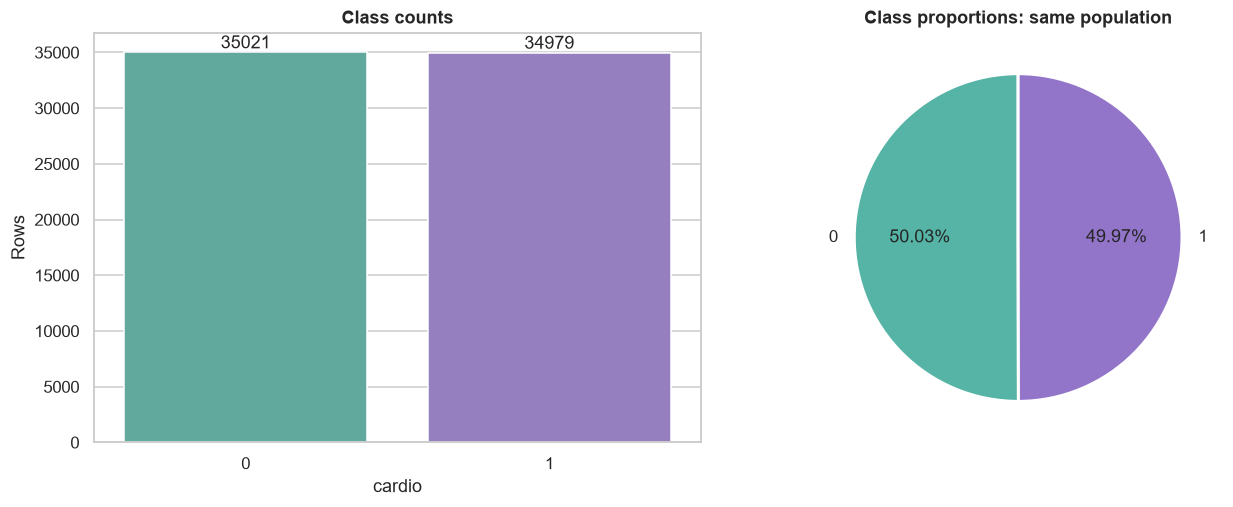

Majority-class baseline on these rows: 50.03%


In [89]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
sns.countplot(data=df, x="cardio", hue="cardio", order=[0, 1],
              palette=class_colors, legend=False, ax=axes[0])
axes[0].set(title="Class counts", xlabel="cardio", ylabel="Rows")
label_bars(axes[0], "%.0f")

if len([0, 1]) <= 5:
    axes[1].pie(target_counts, labels=[0, 1], autopct="%1.2f%%", startangle=90,
                colors=[class_colors[c] for c in [0, 1]],
                wedgeprops={"edgecolor": "white", "linewidth": 2})
    axes[1].set_title("Class proportions: same population")
else:
    axes[1].axis("off")
    axes[1].text(0, 0.5, "Pie omitted: use the countplot and percentage table for many classes.")

plt.show()
print(f"Majority-class baseline on these rows: {target_counts.max()/len(df):.2%}")

One feature at a time: numerical distributions

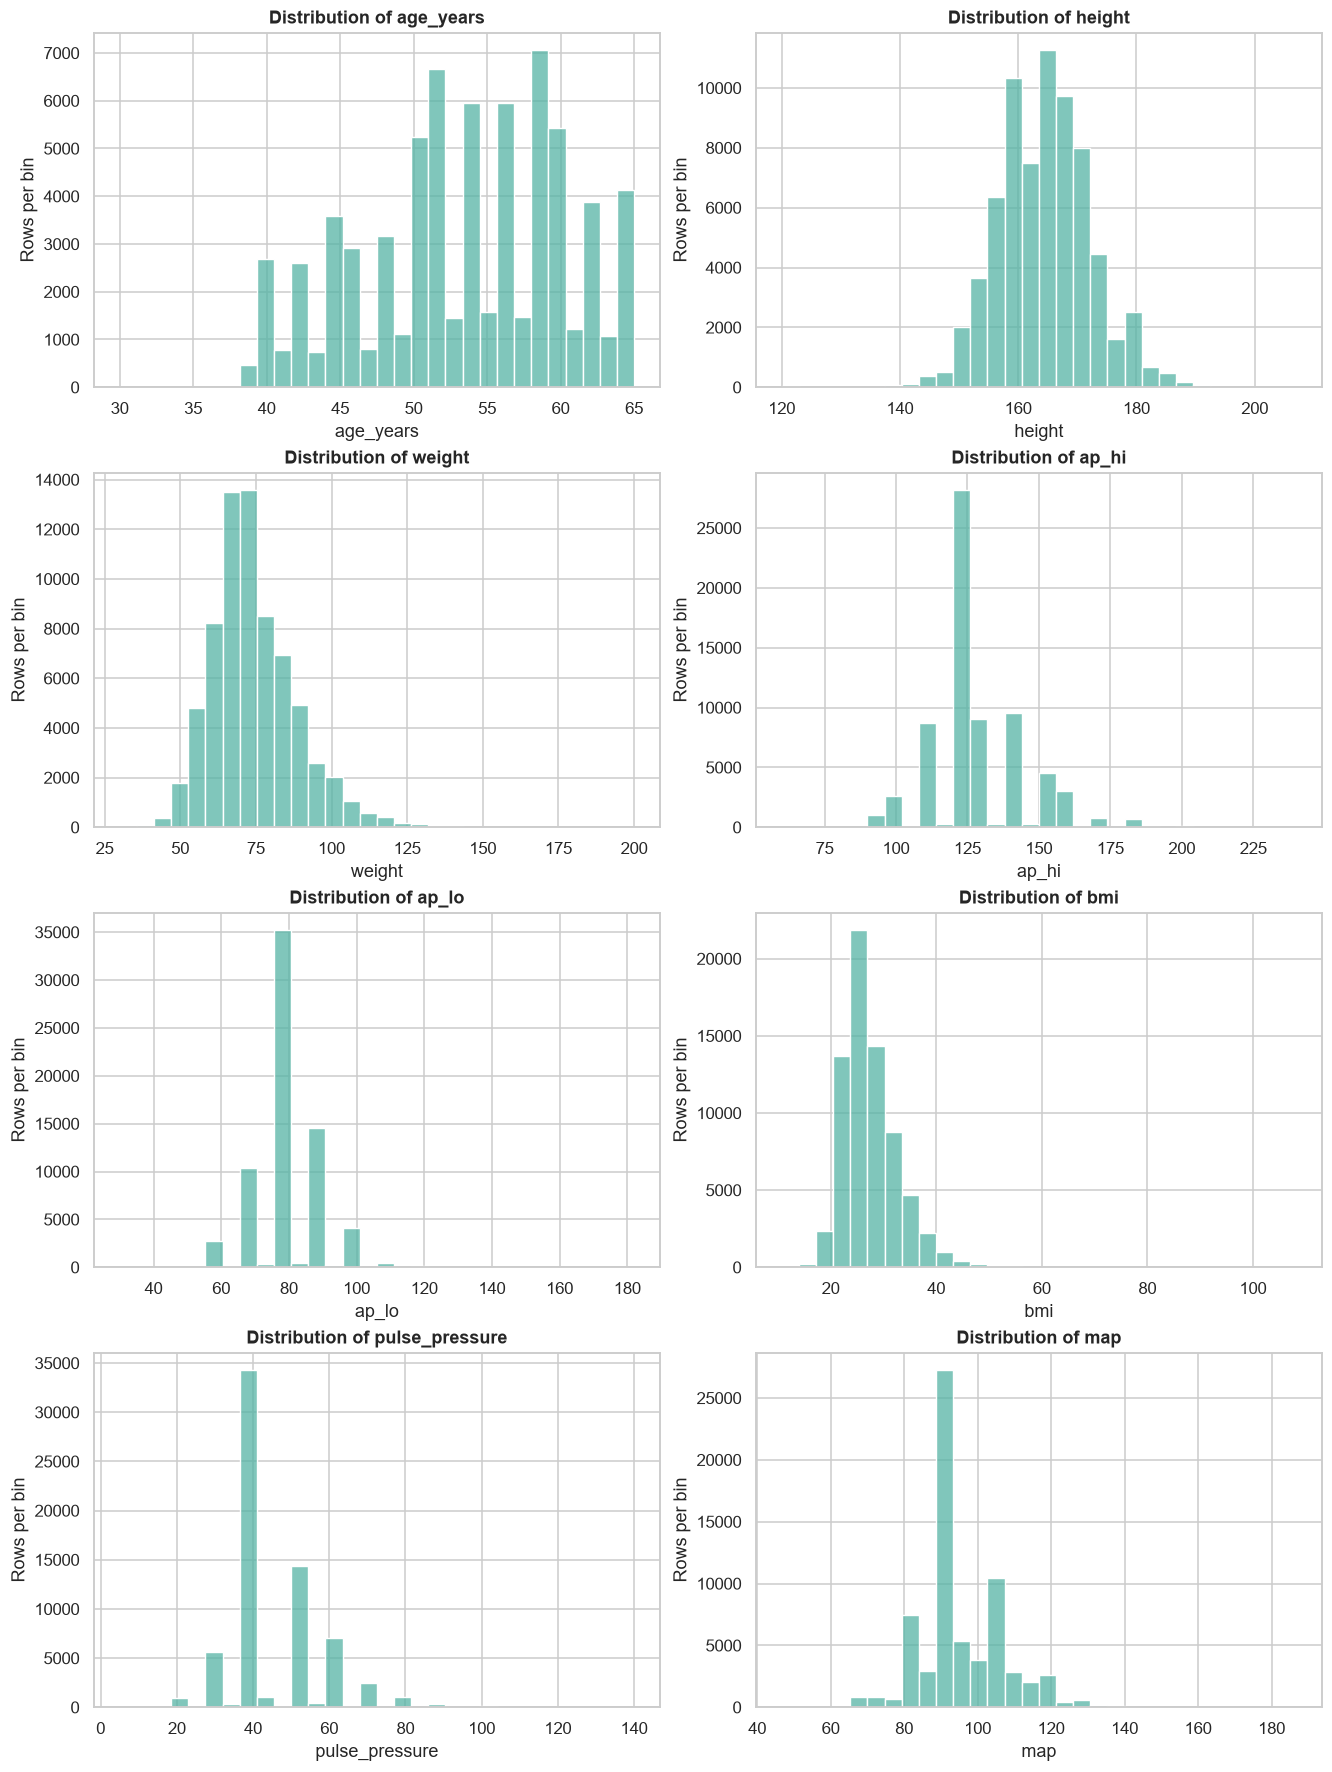

In [90]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES)) # 2 x 2
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.histplot(data=df, x=col, bins=30, color="#55b4a5", ax=ax)
        ax.set(title=f"Distribution of {col}", ylabel="Rows per bin")
    plt.show()

One feature at a time: categorical frequencies

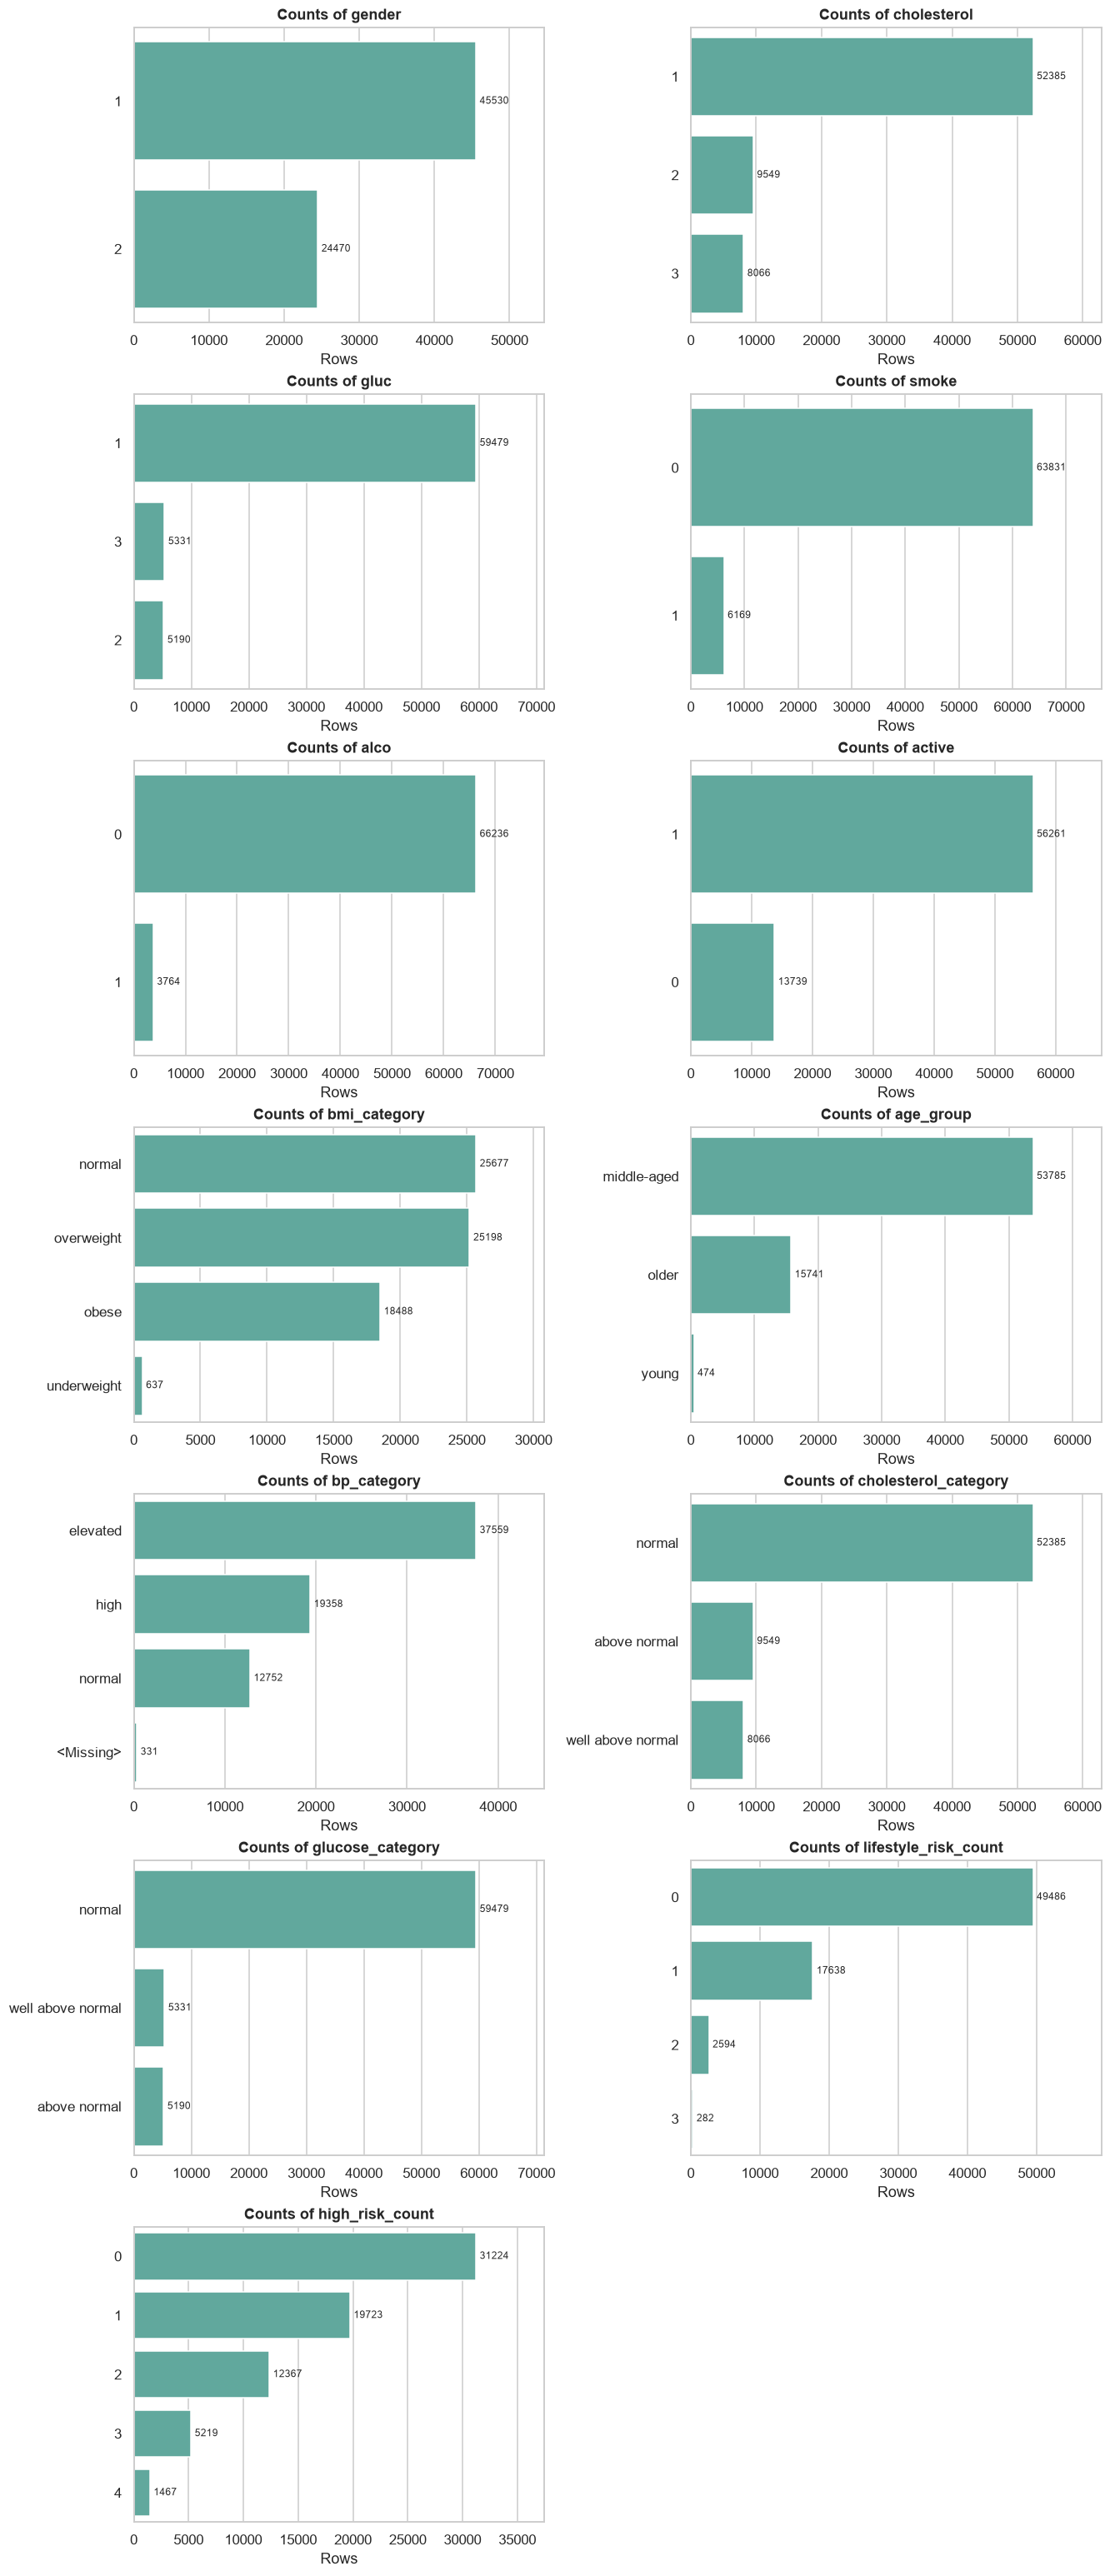

In [91]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES))
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(data=df, y=col, order=category_orders[col], color="#55b4a5", ax=ax)
        ax.set(title=f"Counts of {col}", xlabel="Rows", ylabel="")
        for container in ax.containers:
            ax.bar_label(container, fmt="%.0f", fontsize=8, padding=3)
        ax.margins(x=0.2)
    plt.show()

Boxplots and possible outliers

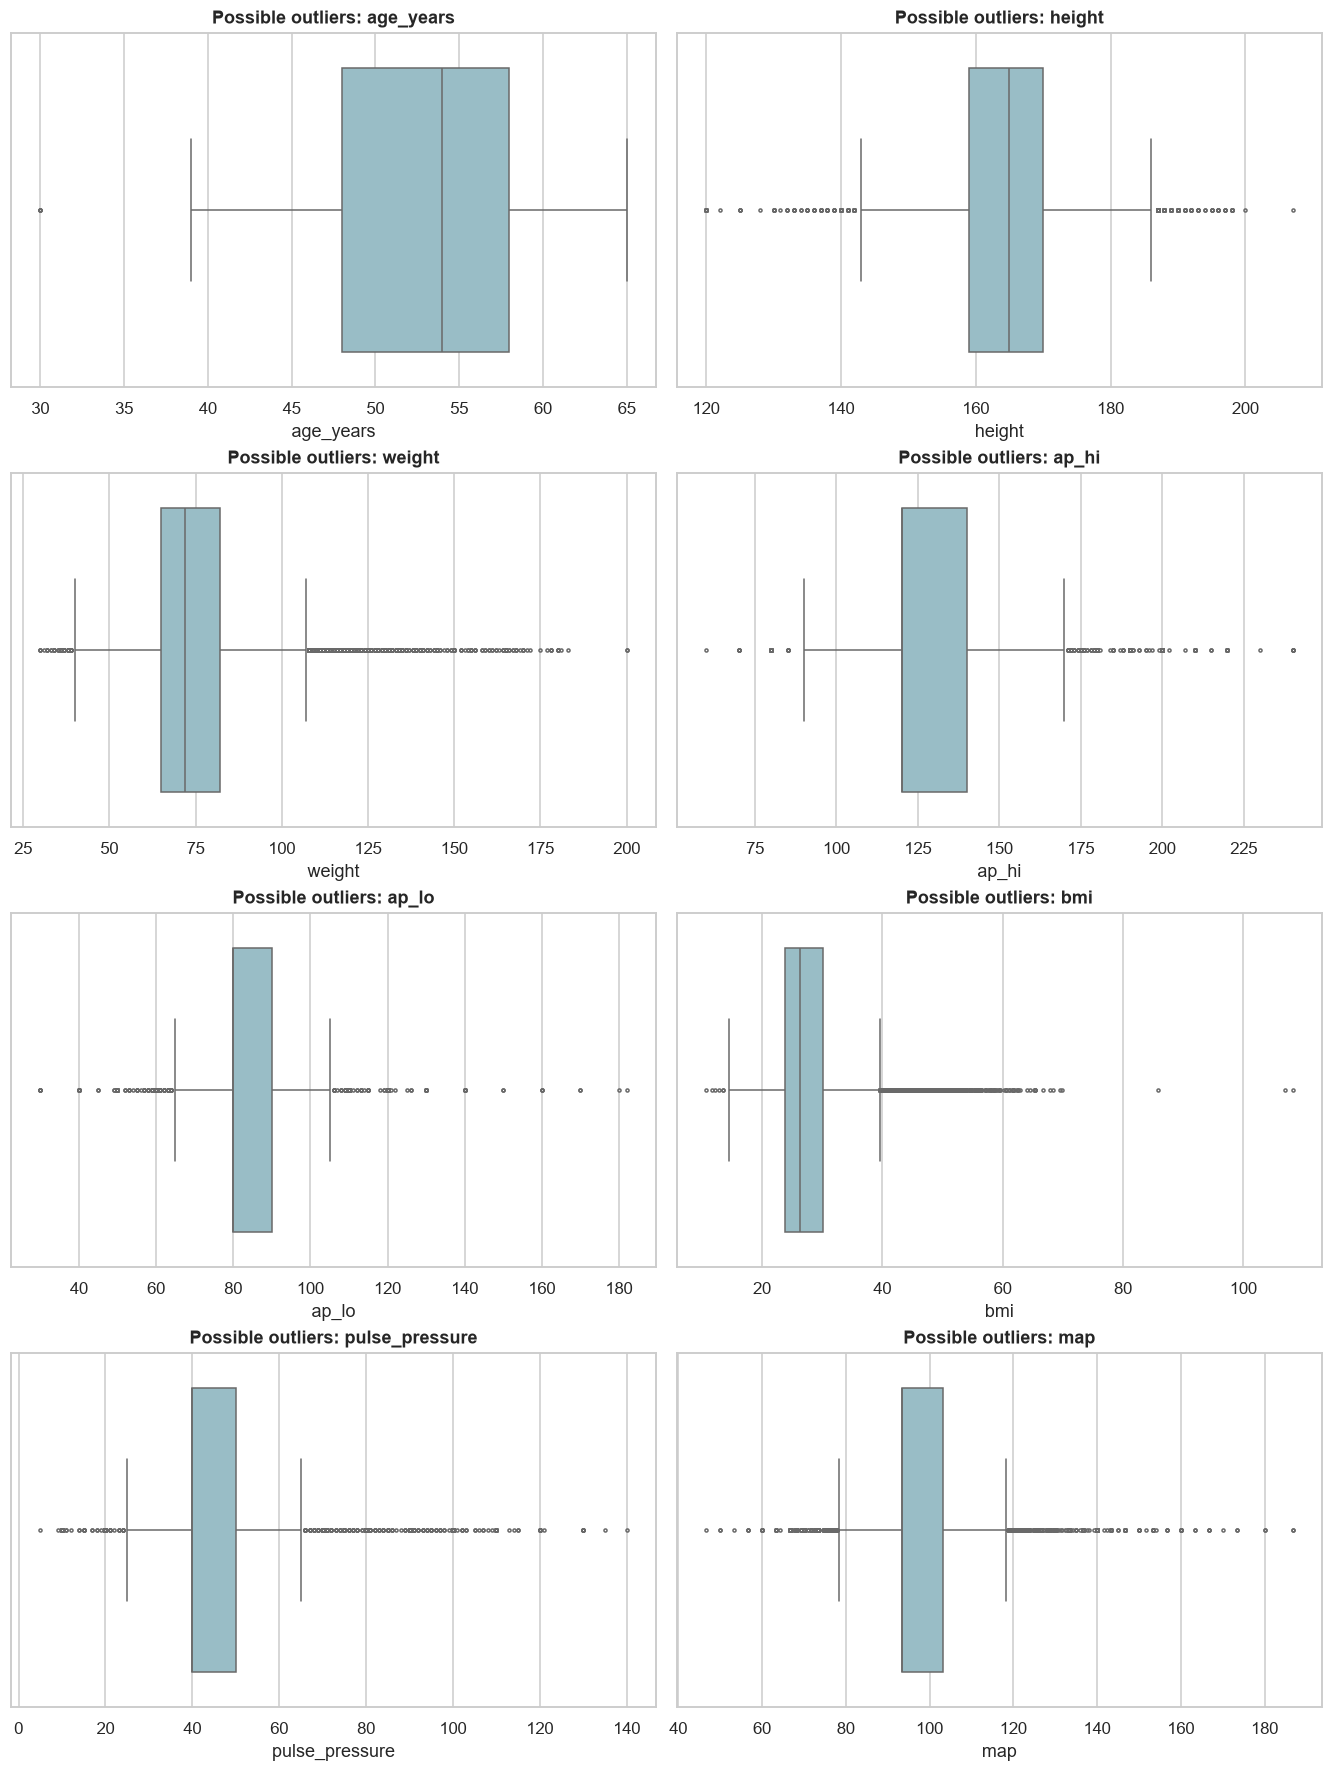

          feature      Q1      Q3   IQR  lower_fence  upper_fence  flagged_n  \
0       age_years   48.00   58.00  10.0        33.00        73.00          4   
1          height  159.00  170.00  11.0       142.50       186.50        466   
2          weight   65.00   82.00  17.0        39.50       107.50       1812   
3           ap_hi  120.00  140.00  20.0        90.00       170.00       1150   
4           ap_lo   80.00   90.00  10.0        65.00       105.00       3532   
5             bmi   23.88   30.18   6.3        14.43        39.63       1997   
6  pulse_pressure   40.00   50.00  10.0        25.00        65.00       5183   
7             map   93.33  103.33  10.0        78.33       118.33       5090   

   observed_n  flagged_pct  
0       70000        0.006  
1       70000        0.666  
2       70000        2.589  
3       69669        1.651  
4       68891        5.127  
5       70000        2.853  
6       68678        7.547  
7       68678        7.411  
Flagged rows have 

In [92]:
outlier_rows = []

if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))

    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.boxplot(data=df, x=col, color="#91c2ce", fliersize=2, ax=ax)
        ax.set_title(f"Possible outliers: {col}")

        x = df[col].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr

        flagged = (x < lower) | (x > upper)

        outlier_rows.append({
            "feature": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_fence": lower,
            "upper_fence": upper,
            "flagged_n": int(flagged.sum()),
            "observed_n": len(x),
            "flagged_pct": flagged.mean()*100
        })

    plt.show()

outlier_summary = pd.DataFrame(outlier_rows)

print(outlier_summary)
print("Flagged rows have been retained.")

Numerical feature versus target: compare entire distributions

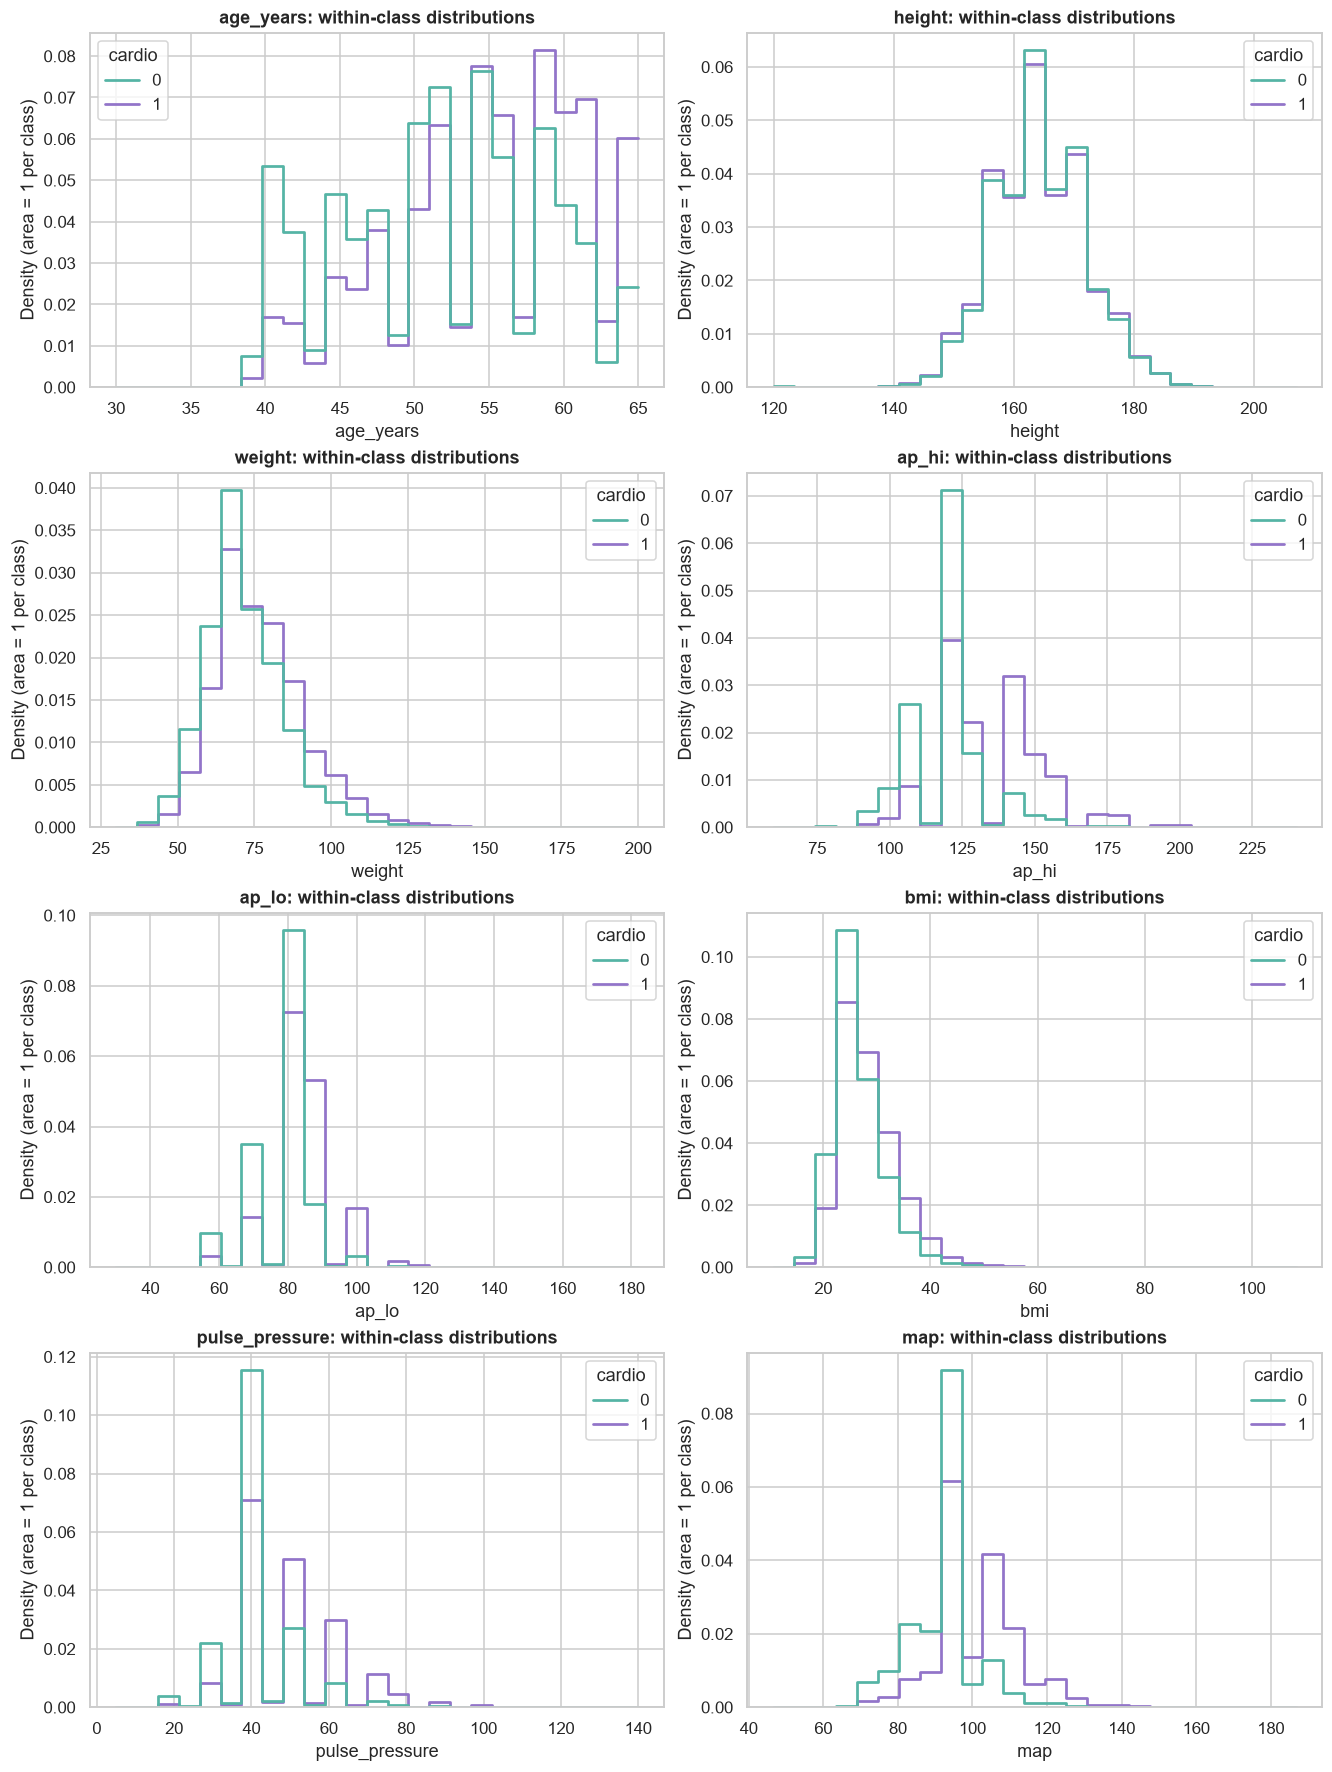

In [93]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))

    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.histplot(
            data=df,
            x=col,
            hue=TARGET,
            hue_order=[0, 1],
            palette=class_colors,
            bins=25,
            stat="density",
            common_norm=False,
            common_bins=True,
            element="step",
            fill=False,
            linewidth=1.8,
            ax=ax
        )

        ax.set(
            title=f"{col}: within-class distributions",
            ylabel="Density (area = 1 per class)"
        )

        if ax.get_legend() is not None:
            ax.get_legend().set_title(TARGET)

    plt.show()

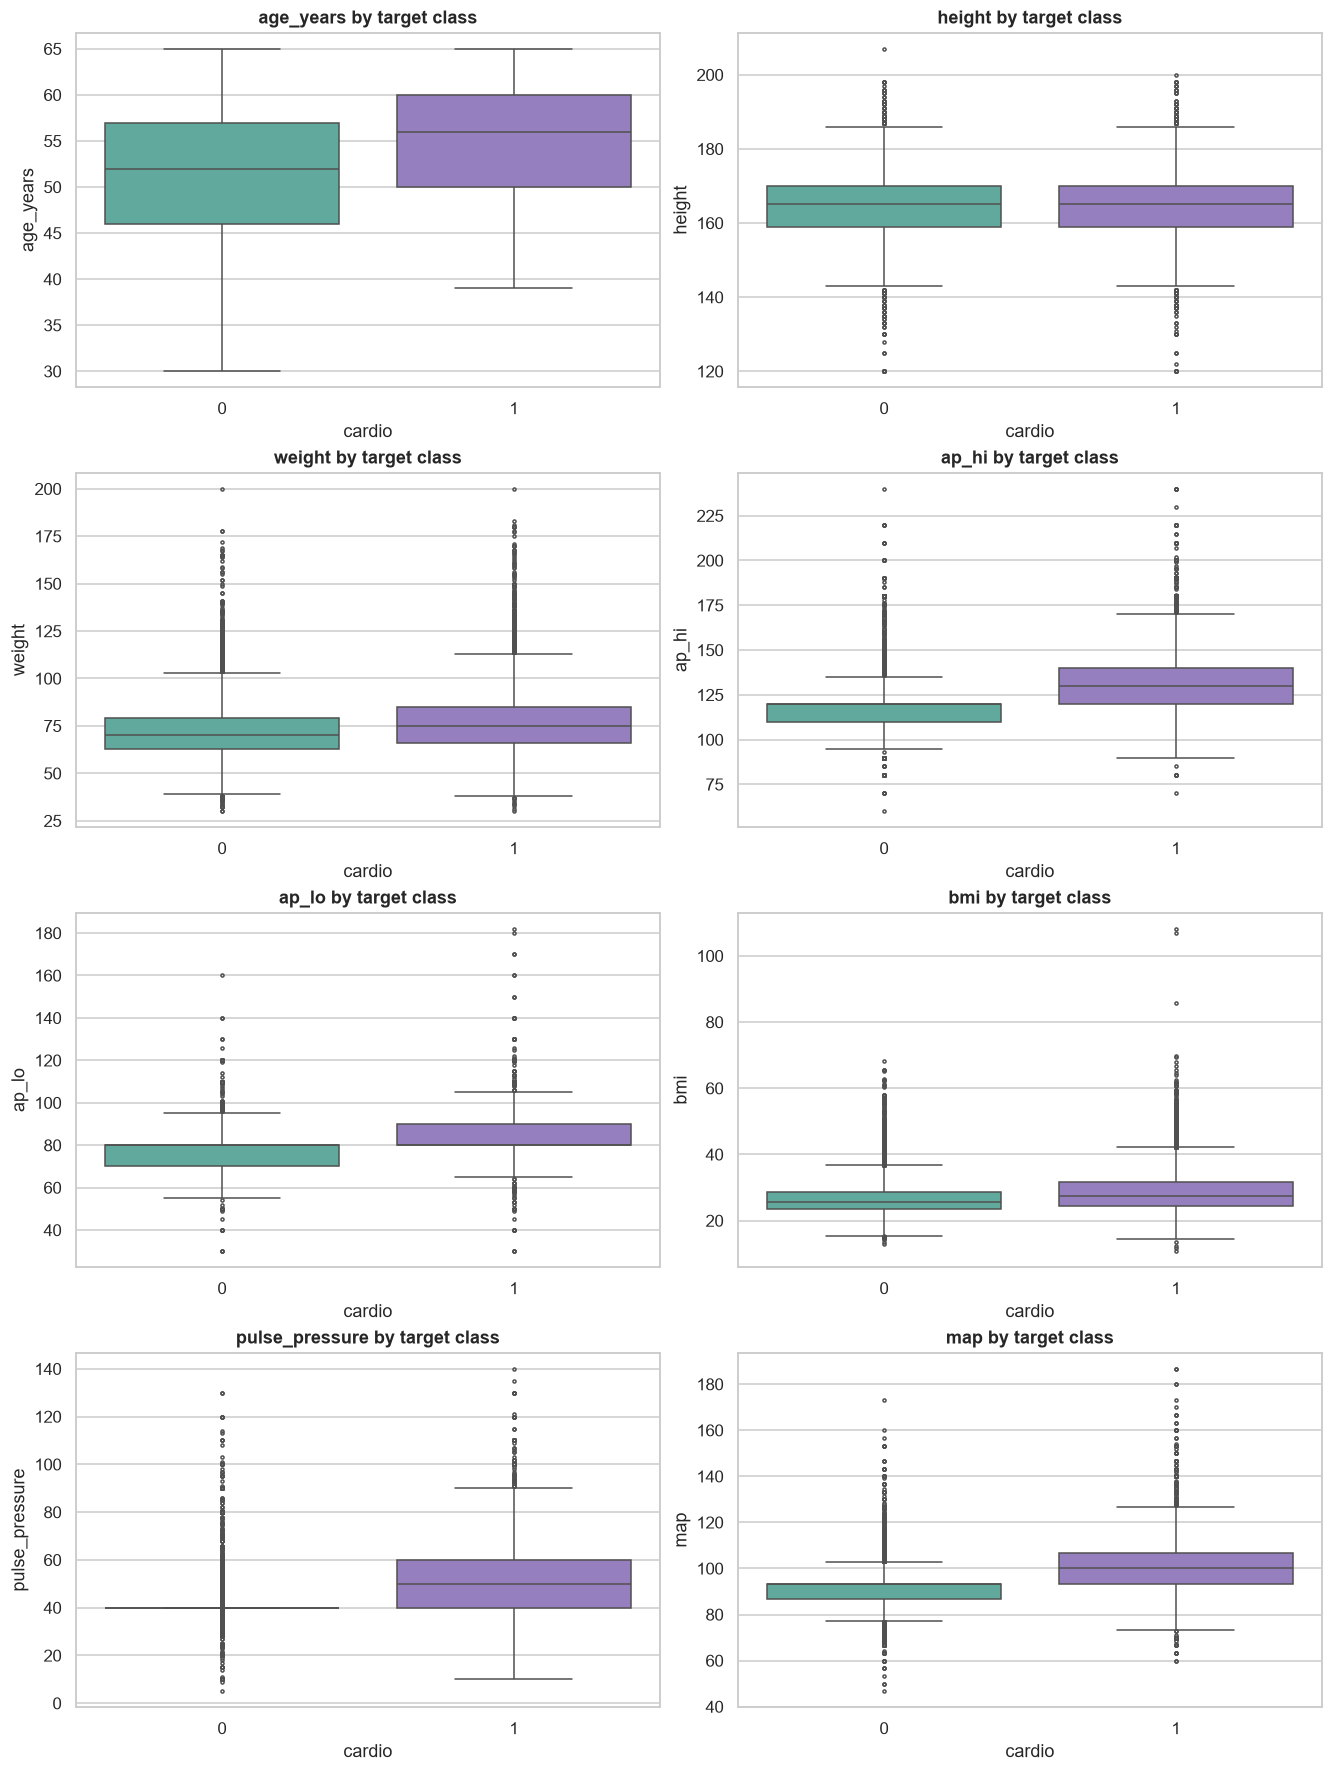

In [94]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))

    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.boxplot(
            data=df,
            x=TARGET,
            y=col,
            order=[0, 1],
            hue=TARGET,
            hue_order=[0, 1],
            palette=class_colors,
            legend=False,
            fliersize=2,
            ax=ax
        )

        ax.set(
            title=f"{col} by target class",
            xlabel=TARGET
        )

    plt.show()

Mean, minimum, and maximum of every numerical feature by target class

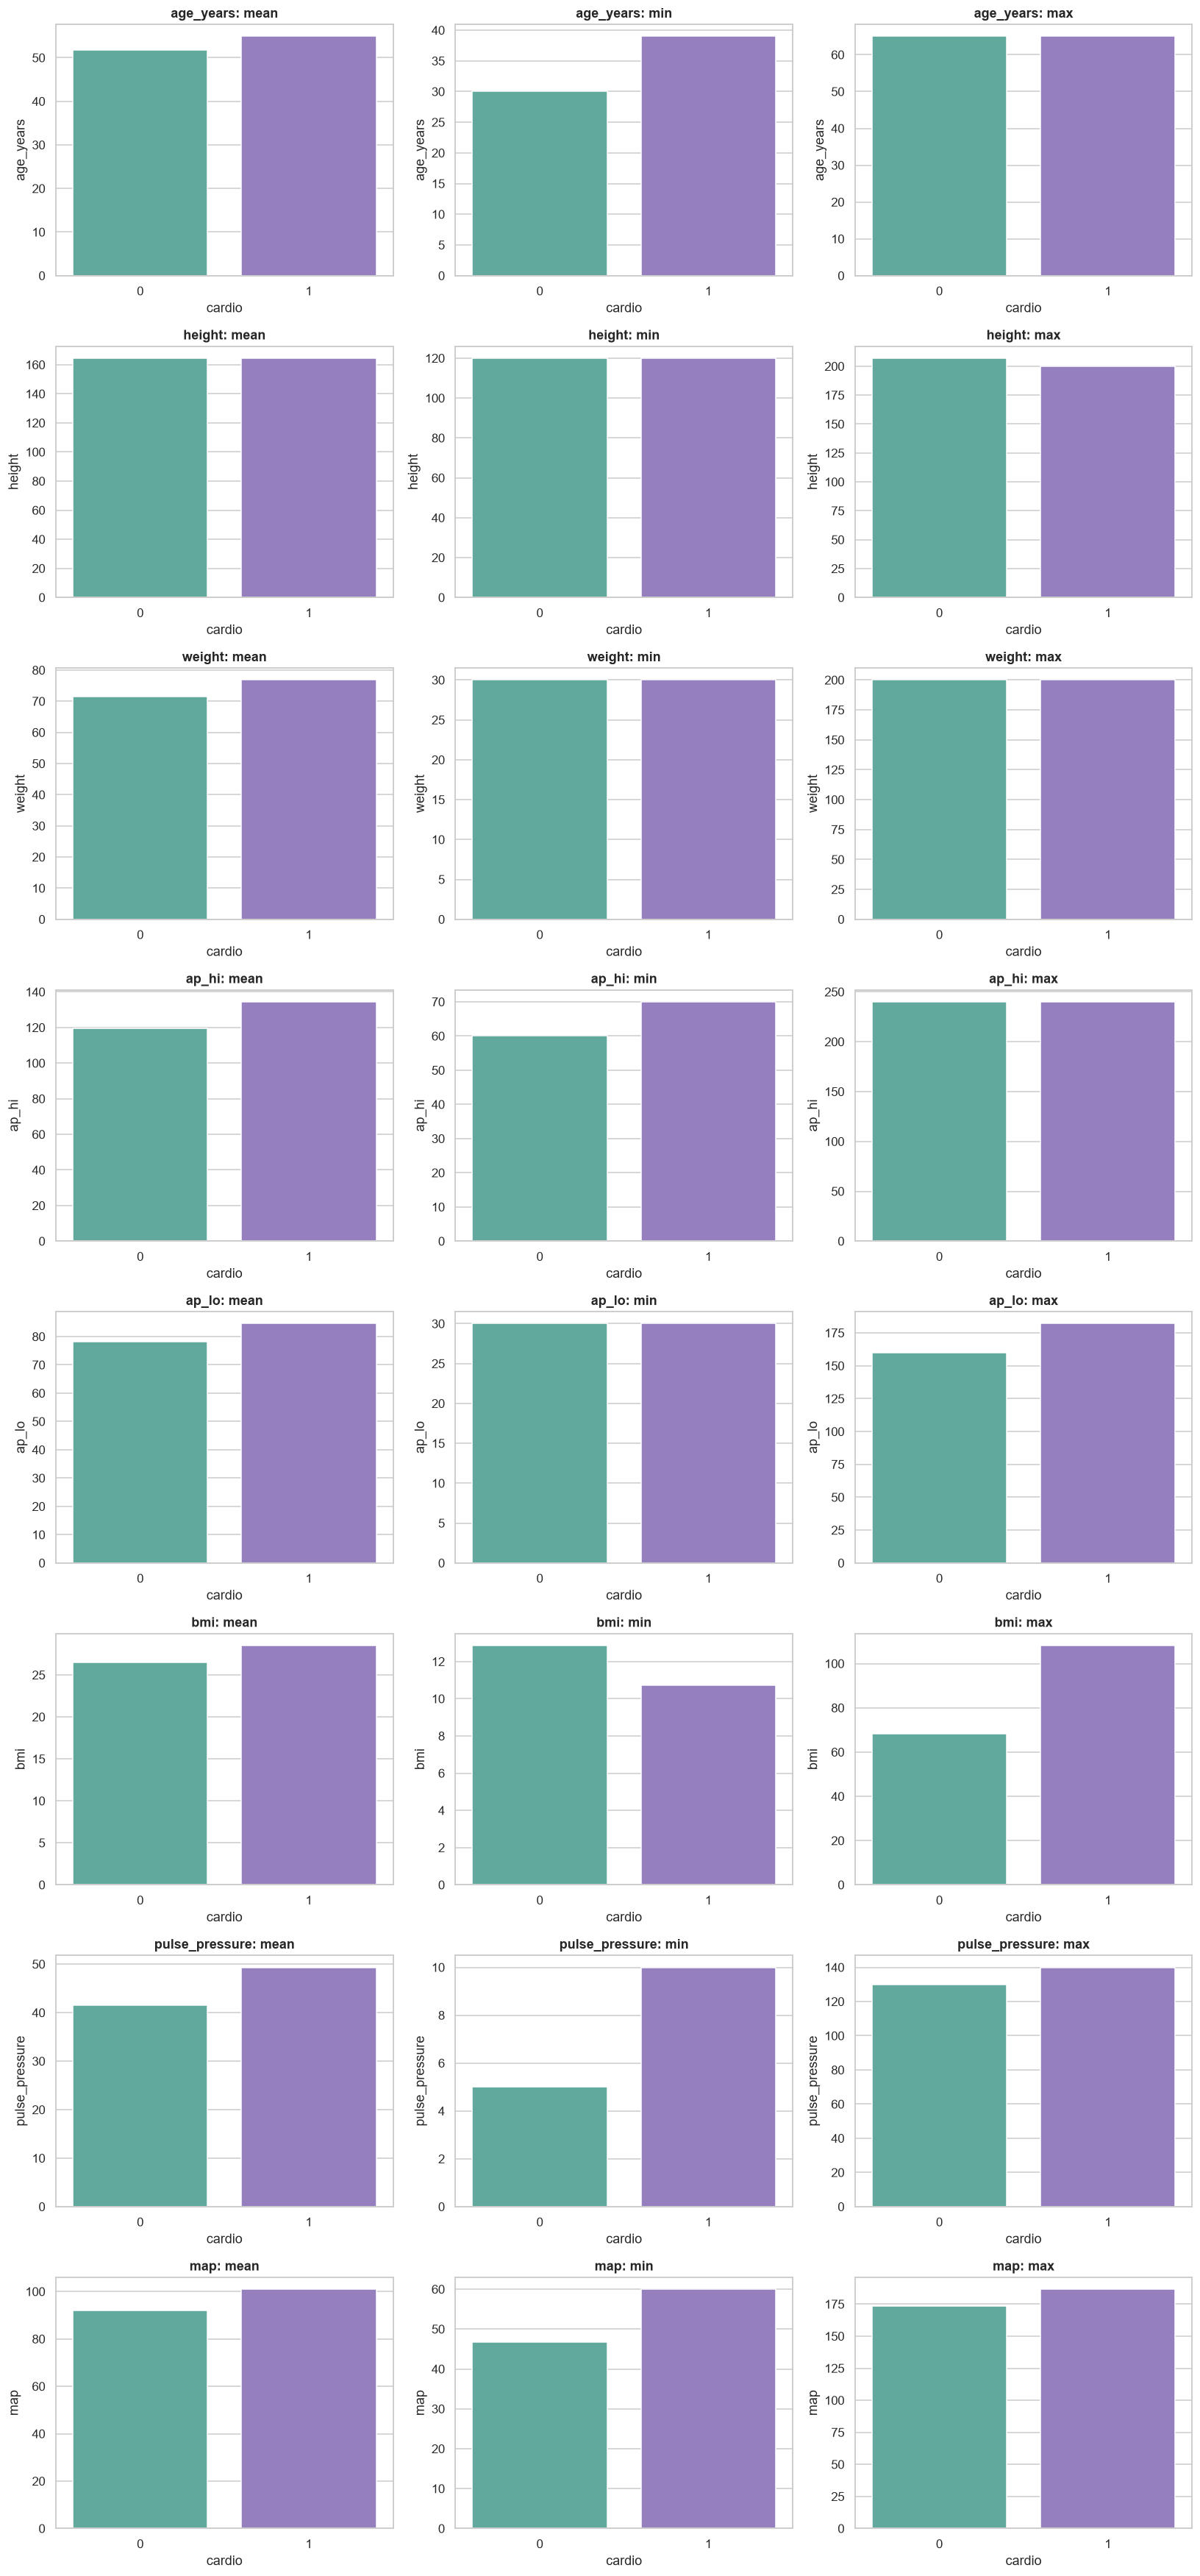

In [95]:
statistics = ["mean", "min", "max"]

plt.figure(figsize=(15, 4 * len(NUMERIC_FEATURES)))

plot_number = 1

for column in NUMERIC_FEATURES:
    for statistic in statistics:
        plt.subplot(len(NUMERIC_FEATURES), 3, plot_number)

        sns.barplot(
            data=df,
            x="cardio",
            y=column,
            hue="cardio",
            order=[0, 1],
            hue_order=[0, 1],
            palette=class_colors,
            estimator=statistic,
            errorbar=None,
            legend=False
        )

        if column in ["lifestyle_risk_count", "high_risk_count"] and statistic == "min":
            plt.ylim(-1,0,1)
        plt.title(f"{column}: {statistic}")
        plt.xlabel("cardio")

        plot_number += 1

plt.tight_layout()
plt.show()

 Categorical feature versus target: counts and rates answer different questions

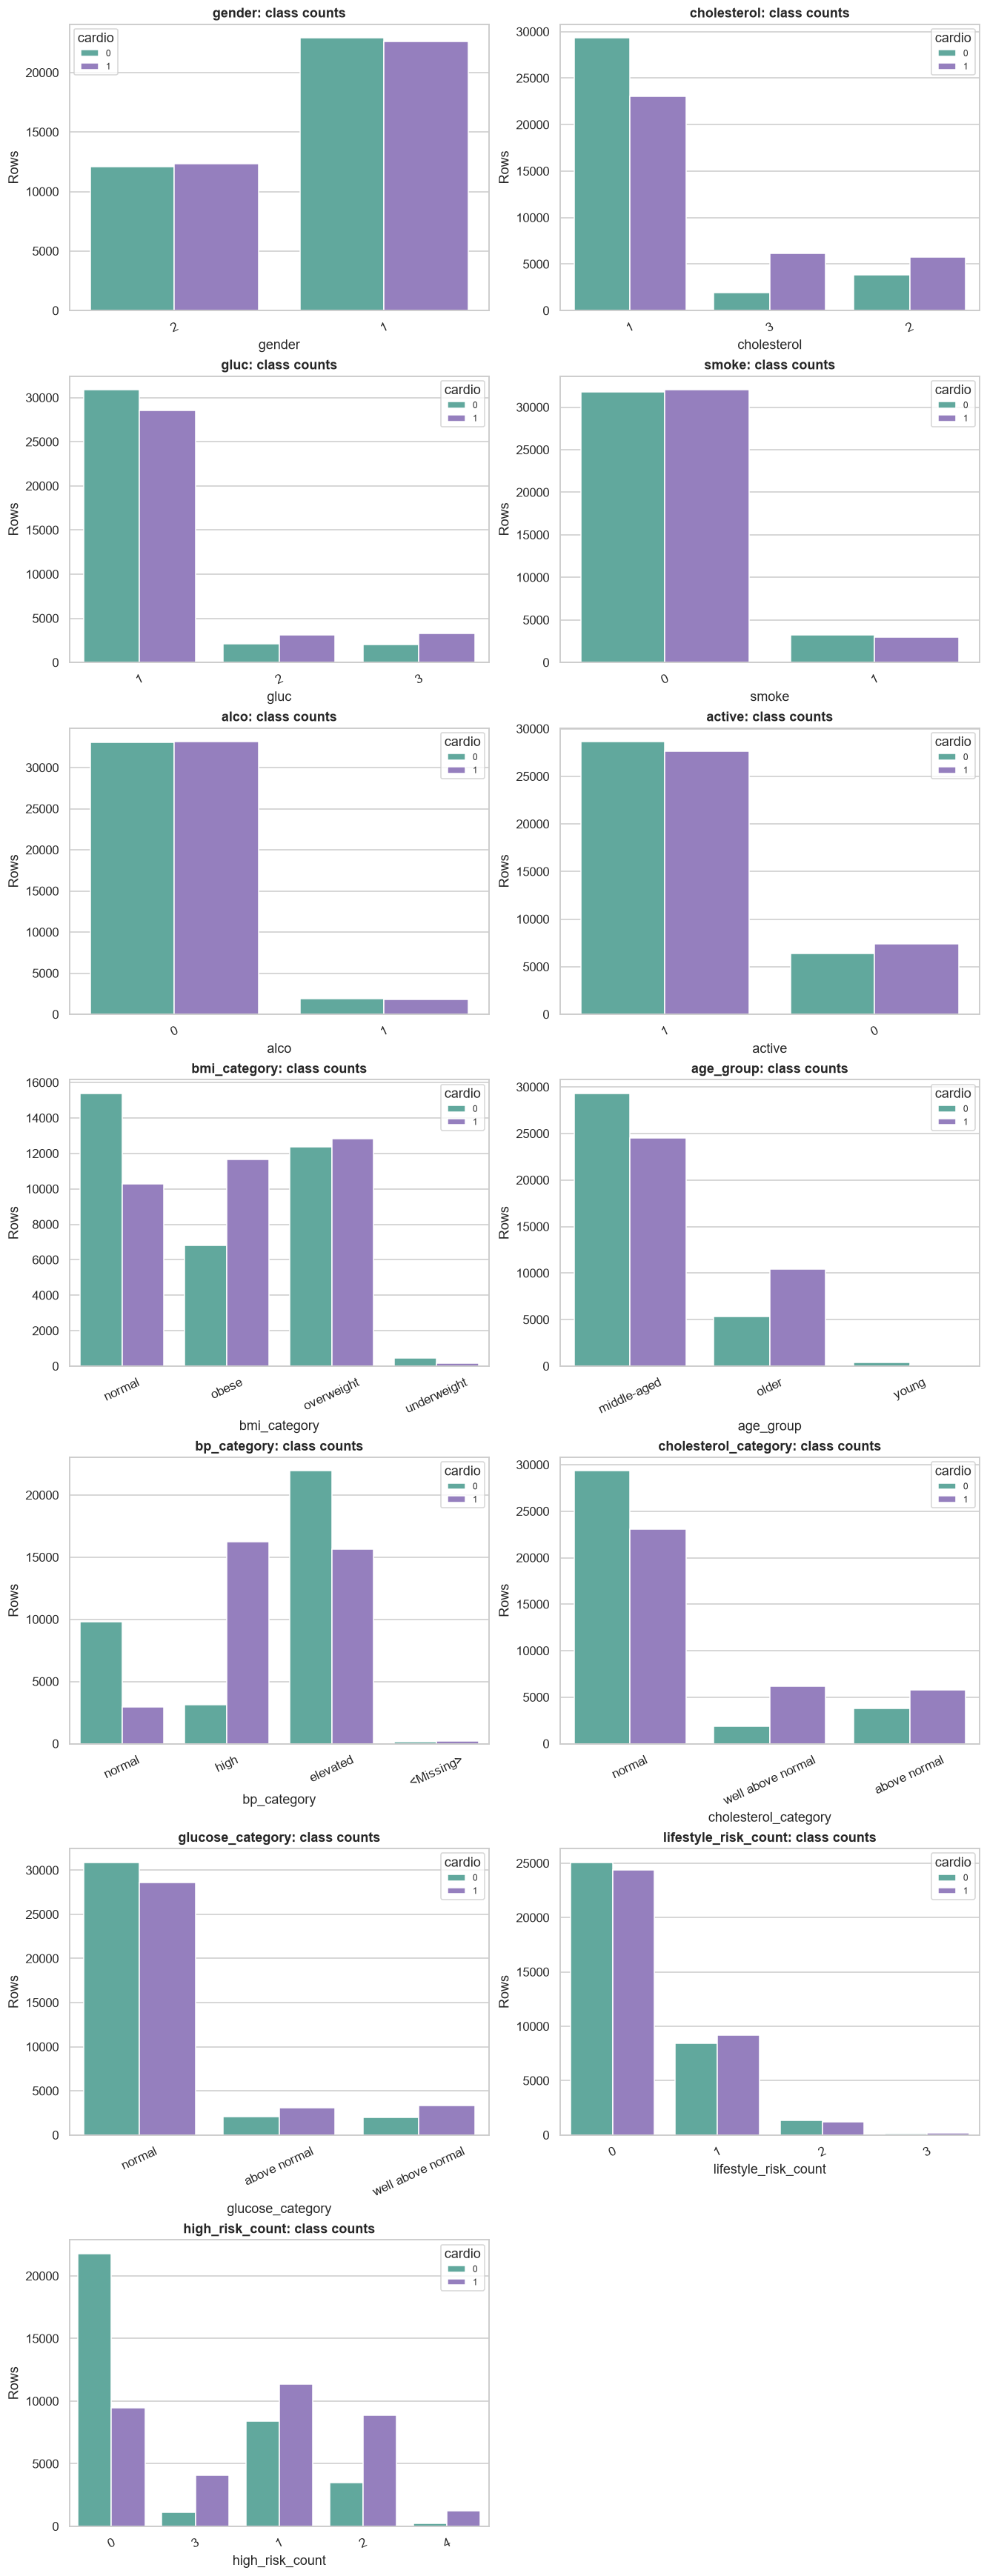

In [97]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES), height=4.5)
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(
            data=df,
            x=col,
            hue="cardio",
            palette=class_colors,
            ax=ax
        )
       
        ax.set(title=f"{col}: class counts", ylabel="Rows")
        ax.tick_params(axis="x", rotation=25)
        ax.legend(title="cardio", fontsize=8)
    plt.show()